# Parkinson's Disease Prediction from Voice, with Explainable AI

**Aim.** Predict Parkinson's disease from sustained-vowel recordings, and explain
what in the voice drives each prediction.

**Answer, in three lines.**

1. It works, at screening strength. On speakers the model has never heard, it reaches
   **ROC-AUC 0.852** and catches **92% of Parkinson's cases** — but flags **half of
   healthy speakers** as suspicious. That specificity is the real limitation.
2. The signal is **impaired pitch control**. `spread1` and `PPE`, two nonlinear
   measures of fundamental-frequency variation, are both higher in Parkinson's with
   Cohen's *d* of 2.03 and 1.91.
3. **One feature is enough.** `spread1` alone reaches **0.924 AUC**, beating the full
   16-feature model at **0.847**. The extra features add variance, not signal.

Everything below is measured, not asserted. All model outputs come from speakers held
out of training, using speaker-grouped cross-validation (Section 6 explains why that
matters and what it costs).

---

## Contents

1. The voice data
2. Which voice measures signal Parkinson's
3. Choosing a model
4. The screening model and its operating point
5. Explaining individual predictions
6. Validity: why the split is grouped by speaker
7. Conclusions and limitations

In [1]:
%matplotlib inline
import sys, json, warnings
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

from config import TABLES_DIR, FIGURES_DIR, RESULTS_DIR
from data import load_raw, add_subject_column, load_dataset
print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 2.3.3 | numpy 2.2.6


## 1. The voice data

195 sustained-vowel phonations from **32 speakers**, 24 with Parkinson's and 8 healthy.
Each speaker contributed 6 or 7 recordings in a single session. Each recording is
summarised by 22 acoustic measures: pitch statistics, jitter (pitch instability),
shimmer (loudness instability), noise ratios, and four nonlinear dynamical measures.

In [2]:
raw = load_raw()
df = add_subject_column(raw)
per_speaker = df.groupby("subject").agg(n_recordings=("name", "size"),
                                        status=("status", "first"))

print(f"recordings : {len(raw)}")
print(f"speakers   : {len(per_speaker)}  "
      f"({int((per_speaker.status==1).sum())} Parkinson's, "
      f"{int((per_speaker.status==0).sum())} healthy)")
print(f"recordings per speaker: {per_speaker.n_recordings.min()}"
      f"-{per_speaker.n_recordings.max()}")
print(f"\nrecording-level prevalence: {raw.status.mean():.1%} Parkinson's")
print("A model that always says 'Parkinson's' is therefore already "
      f"{raw.status.mean():.1%} accurate — accuracy alone is uninformative here.")

X, y, groups, meta = load_dataset()
print(f"\nafter removing 6 algebraically redundant columns: {X.shape[1]} features")

recordings : 195
speakers   : 32  (24 Parkinson's, 8 healthy)
recordings per speaker: 6-7

recording-level prevalence: 75.4% Parkinson's
A model that always says 'Parkinson's' is therefore already 75.4% accurate — accuracy alone is uninformative here.

after removing 6 algebraically redundant columns: 16 features


## 2. Which voice measures signal Parkinson's

Before any model, the direct question: does each acoustic measure differ between
groups, in which direction, and by how much?

Features are averaged within each speaker first, so these statistics count 32
independent people rather than 195 correlated recordings.

In [3]:
uni = pd.read_csv(TABLES_DIR / "biomarker_univariate.csv")
cols = ["plain_name", "feature", "direction", "cohens_d", "auc_single_feature",
        "healthy_mean", "parkinsons_mean"]
display(uni[cols].head(10).round(3))

,plain_name,feature,direction,cohens_d,auc_single_feature,healthy_mean,parkinsons_mean
0,Pitch-variation measure 1,spread1,higher in PD,2.033,0.927,-6.759,-5.346
1,Pitch-period entropy,PPE,higher in PD,1.910,0.922,0.123,0.233
2,Amplitude perturbation,MDVP:APQ,higher in PD,1.220,0.875,0.013,0.027
3,Pitch-variation measure 2,spread2,higher in PD,1.459,0.859,0.160,0.246
4,Loudness instability,MDVP:Shimmer,higher in PD,1.235,0.828,0.018,0.033
5,Pitch perturbation,MDVP:PPQ,higher in PD,0.922,0.807,0.002,0.004
6,Pitch instability (abs),MDVP:Jitter(Abs),higher in PD,1.092,0.807,0.000,0.000
7,Signal complexity,D2,higher in PD,1.067,0.786,2.154,2.444
8,Noise-to-harmonics,NHR,higher in PD,0.575,0.786,0.011,0.029
9,Pitch instability,MDVP:Jitter(%),higher in PD,0.881,0.776,0.004,0.007


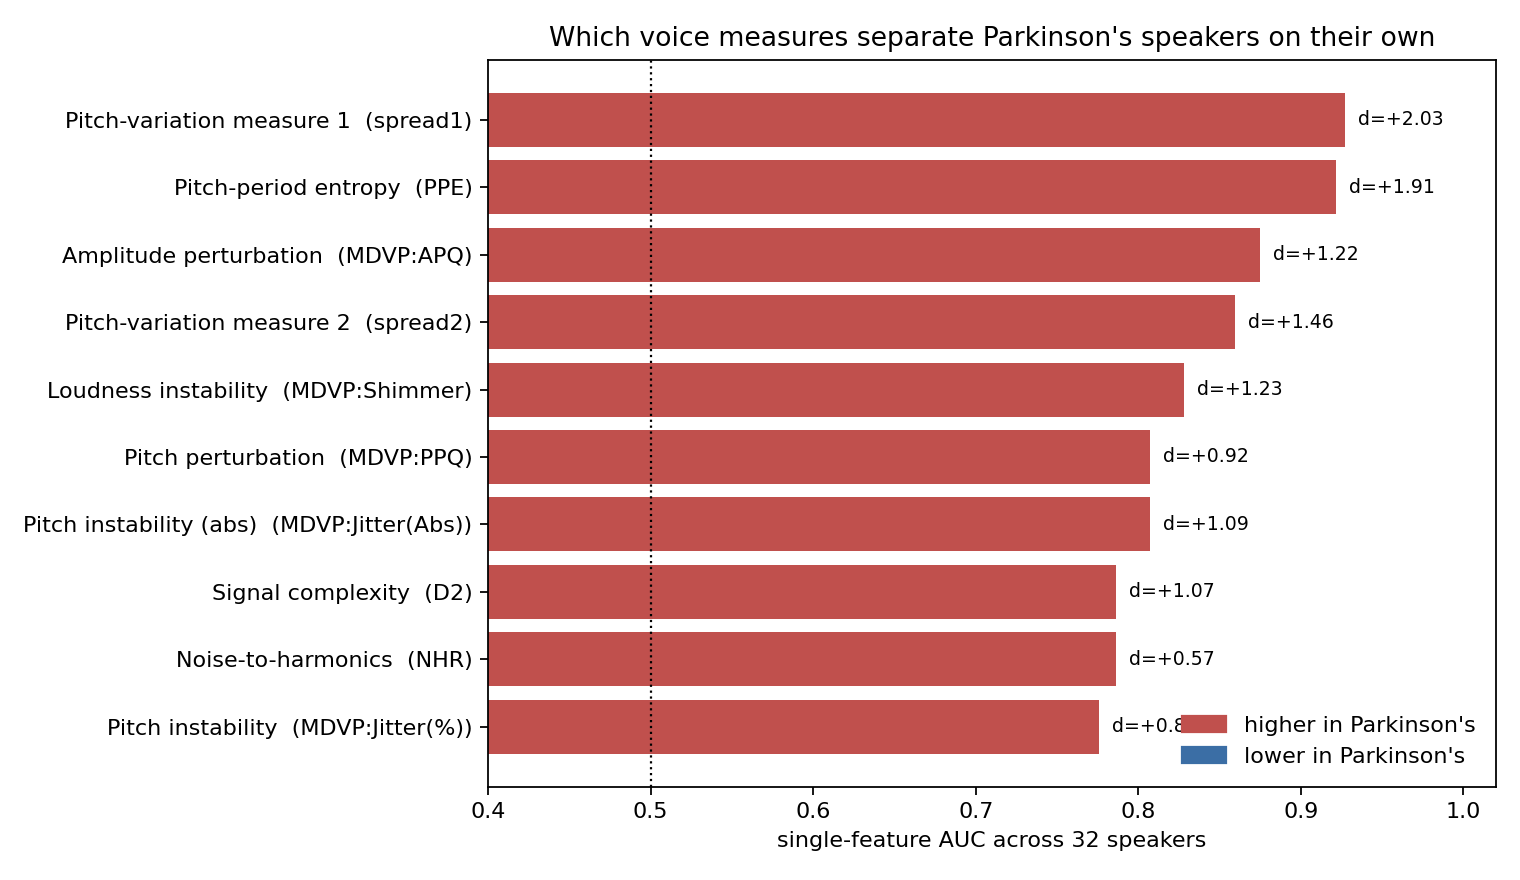

In [4]:
display(Image(filename=str(FIGURES_DIR / "biomarker_separation.png")))

**The clinical reading.** The strongest signals are not the classical jitter and
shimmer perturbation measures — they are `spread1` and `PPE`, both nonlinear
descriptors of how erratically the fundamental frequency moves. Both are *higher*
in Parkinson's, with very large effect sizes (*d* = 2.03 and 1.91).

That is consistent with the pathophysiology: Parkinson's disrupts the fine motor
control of the laryngeal muscles, so pitch becomes harder to hold steady. Loudness
instability (`MDVP:Shimmer`, *d* = 1.24) and amplitude perturbation (`MDVP:APQ`,
*d* = 1.22) follow the same pattern, one tier down.

## 3. Choosing a model

Twelve classifiers, all evaluated identically: 4-fold x 10-repeat **nested**
cross-validation, grouped by speaker, with hyper-parameters tuned by an inner CV that
obeys the same grouping. 960 fold evaluations in total.

In [5]:
folds = pd.read_csv(TABLES_DIR / "cv_folds.csv")
honest = folds[folds.protocol == "subject"]
board = (honest.groupby("model")[["roc_auc", "balanced_accuracy",
                                  "sensitivity", "specificity", "mcc"]]
         .agg(["mean", "std"]))
board.columns = [f"{a}_{b}" for a, b in board.columns]
board = board[["roc_auc_mean", "roc_auc_std", "balanced_accuracy_mean",
               "sensitivity_mean", "specificity_mean", "mcc_mean"]]
display(board.sort_values("roc_auc_mean", ascending=False).round(3))

,roc_auc_mean,roc_auc_std,balanced_accuracy_mean,sensitivity_mean,specificity_mean,mcc_mean
model,,,,,,
Logistic Regression,0.819,0.117,0.674,0.761,0.563,0.284
Extra Trees,0.817,0.114,0.664,0.867,0.429,0.291
SVM (RBF),0.815,0.130,0.683,0.715,0.638,0.303
Gaussian NB,0.795,0.159,0.728,0.705,0.748,0.372
SVM (linear),0.788,0.129,0.648,0.742,0.528,0.232
MLP,0.781,0.119,0.674,0.870,0.450,0.306
Random Forest,0.781,0.108,0.637,0.899,0.335,0.249
k-NN,0.762,0.124,0.634,0.922,0.303,0.240
XGBoost,0.717,0.212,0.670,0.912,0.394,0.314


**Logistic regression wins.** It beats every ensemble, the SVM and the neural network.
At 32 speakers and 16 features there is not enough data for flexible models to find
anything a linear boundary misses, and they pay for the attempt in variance.

Logistic regression is therefore the deployed model for the rest of this notebook.
It is also the most explainable choice, which here costs nothing.

## 4. The screening model and its operating point

A screening test is defined by its operating point, not by its accuracy. The threshold
is tuned to reach **90% sensitivity**, and the cost in specificity is then measured.

The threshold is chosen *nested*: inside every outer fold it is fitted on an inner
cross-validation of the training speakers only, then frozen and applied to the
held-out speakers. Choosing a threshold on the same data used to report it would
be a subtle leak.

In [6]:
scr = json.loads((RESULTS_DIR / "screening_report.json").read_text())
print(f"model      : {scr['model']}")
print(f"threshold  : {scr['threshold_mean']:.3f} +/- {scr['threshold_sd']:.3f} "
      f"(chosen independently in each of {scr['n_outer_folds']} folds)")

rows = []
for level in ["recording_level", "speaker_level"]:
    d = scr[level]
    rows.append({"level": level.replace("_level", ""),
                 "ROC-AUC": f"{d['roc_auc']:.3f} +/- {d['roc_auc_sd']:.3f}",
                 "sensitivity": f"{d['sensitivity']:.3f} +/- {d['sensitivity_sd']:.3f}",
                 "specificity": f"{d['specificity']:.3f} +/- {d['specificity_sd']:.3f}",
                 "PPV": f"{d['ppv']:.3f}", "NPV": f"{d['npv']:.3f}"})
display(pd.DataFrame(rows))

print("\nCalibration:", json.dumps(scr["calibration"]))

model      : Logistic Regression
threshold  : 0.394 +/- 0.046 (chosen independently in each of 40 folds)


,level,ROC-AUC,sensitivity,specificity,PPV,NPV
0,recording,0.834 +/- 0.021,0.897 +/- 0.023,0.483 +/- 0.068,0.842,0.608
1,speaker,0.852 +/- 0.035,0.921 +/- 0.024,0.487 +/- 0.040,0.844,0.677



Calibration: {"brier_score": 0.1652, "mean_predicted": 0.5783, "observed_prevalence": 0.7538}


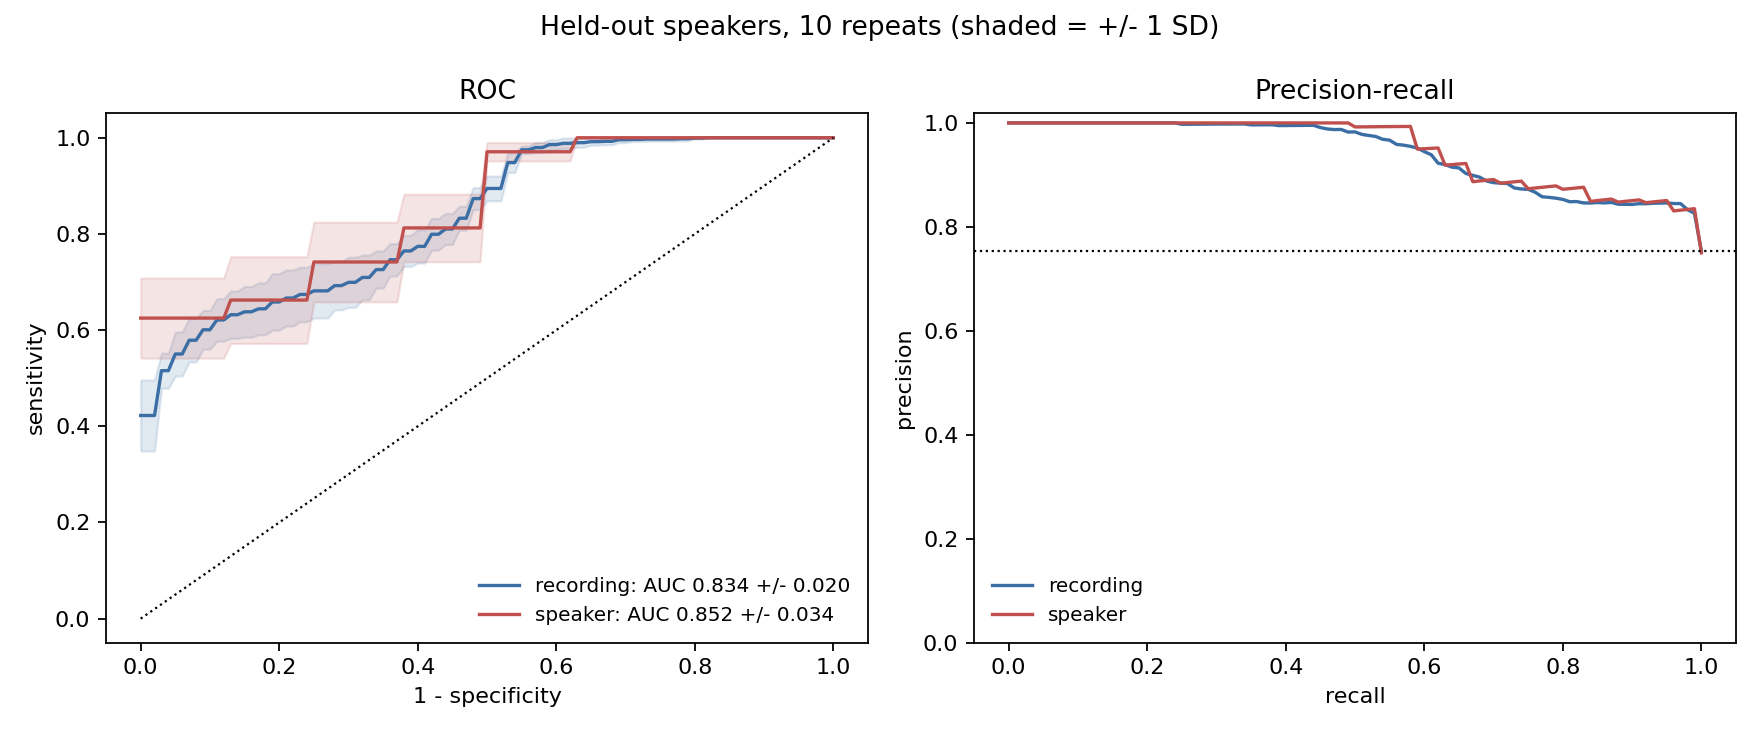

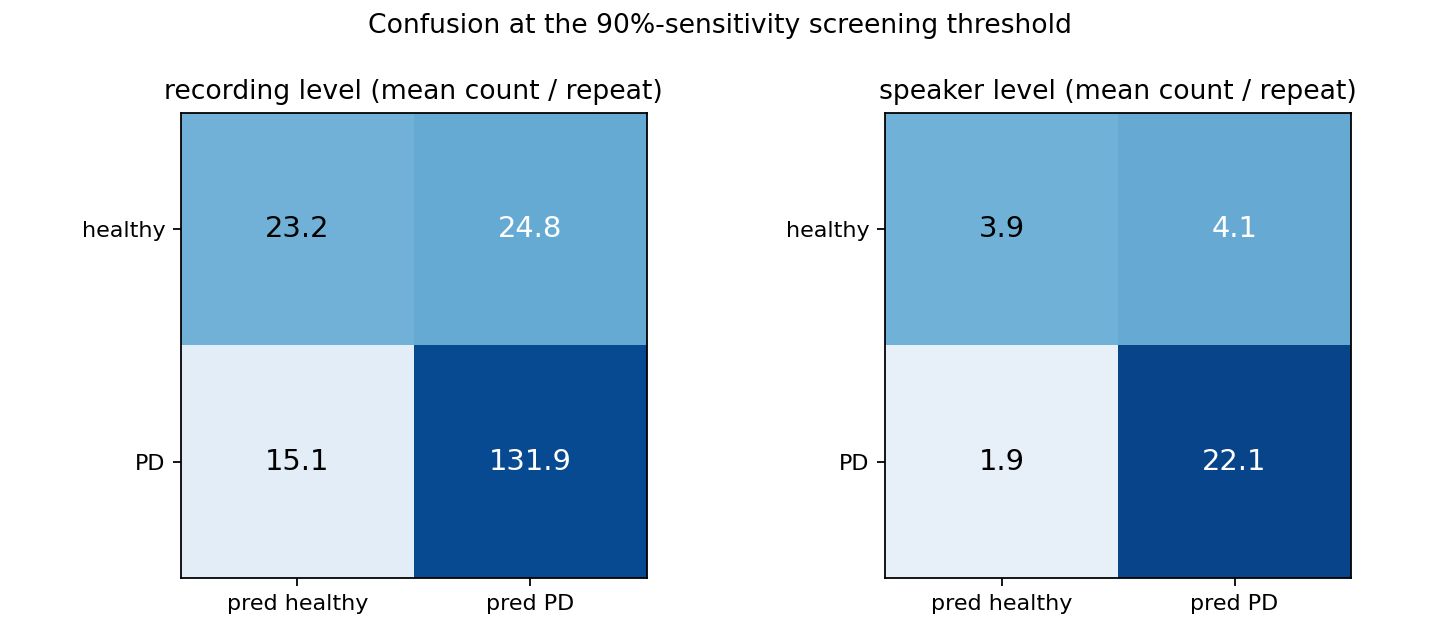

In [7]:
display(Image(filename=str(FIGURES_DIR / "screening_curves.png")))
display(Image(filename=str(FIGURES_DIR / "screening_confusion.png")))

**What this test would actually do.** Per repeat, among the 8 held-out healthy
speakers it correctly clears about 3.9 and wrongly flags about 4.1. Among the 24
with Parkinson's it catches about 22.1 and misses about 1.9.

So: it rarely misses a case, and it cries wolf about half the time on healthy
speakers. As a triage step before clinical assessment that may be acceptable. As a
standalone diagnostic it is not, and no accuracy figure would have made that visible.

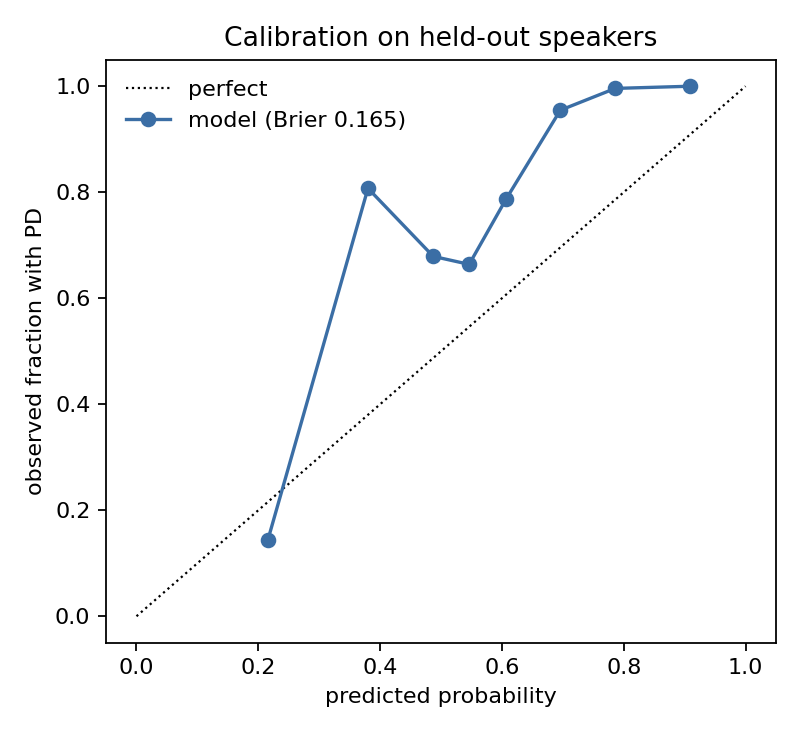

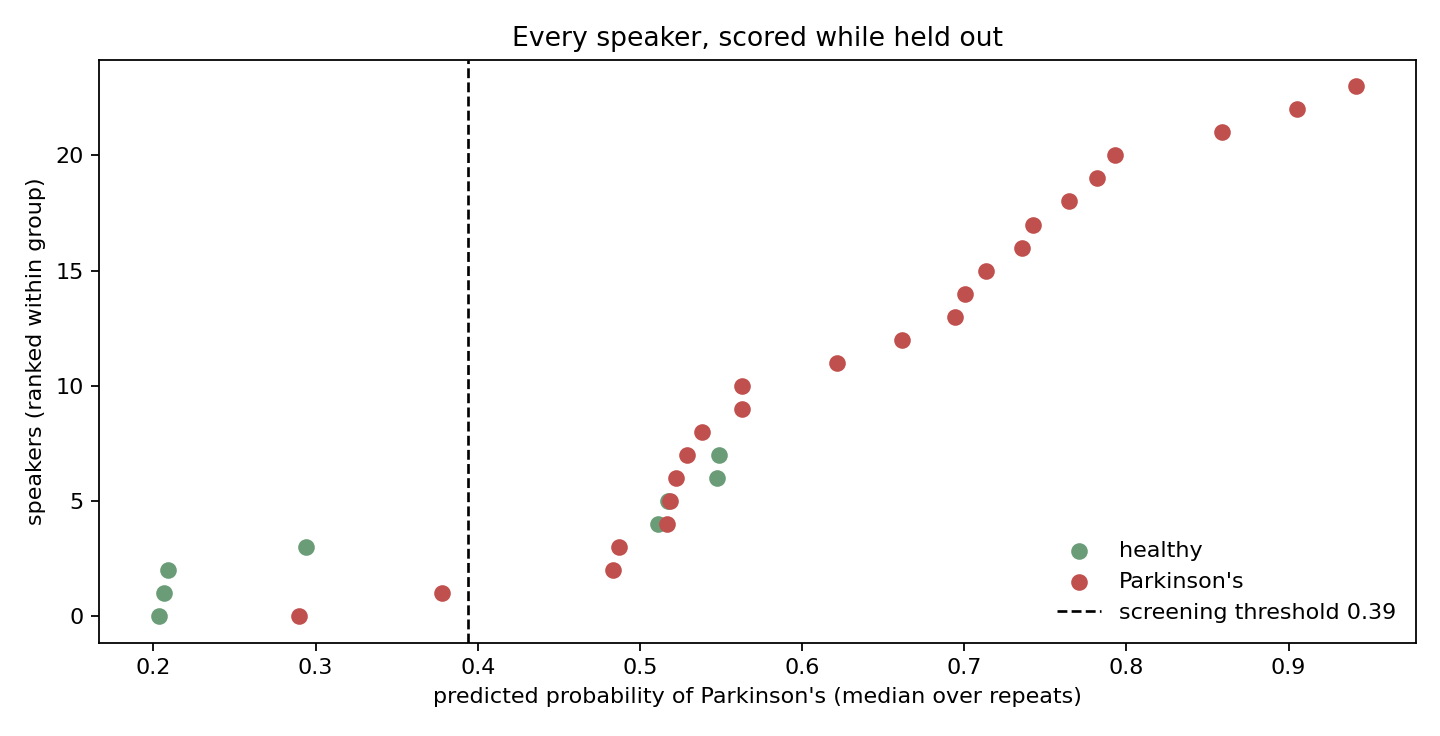

In [8]:
display(Image(filename=str(FIGURES_DIR / "screening_calibration.png")))
display(Image(filename=str(FIGURES_DIR / "screening_risk_distribution.png")))

The risk plot shows every speaker scored while held out. The two groups overlap in a
band roughly between 0.3 and 0.6 — that overlap *is* the specificity problem, and it
is a property of the data, not of the classifier.

## 5. Explaining individual predictions

Feature importance without a sign is not a clinical finding. Below, SHAP values are
computed from the deployed logistic regression on held-out speakers, so the direction
of every effect is explicit.

In [9]:
signed = pd.read_csv(TABLES_DIR / "biomarker_model_attribution.csv")
display(signed[["plain_name", "feature", "mean_abs_shap", "effect_direction",
                "value_shap_corr"]].head(10).round(4))

,plain_name,feature,mean_abs_shap,effect_direction,value_shap_corr
0,Pitch-variation measure 1,spread1,0.1546,raises PD risk when high,0.9926
1,Pitch-period entropy,PPE,0.1412,raises PD risk when high,0.9904
2,Pitch-variation measure 2,spread2,0.1219,raises PD risk when high,0.9733
3,Signal complexity,D2,0.0984,raises PD risk when high,0.9661
4,Average pitch,MDVP:Fo(Hz),0.0966,lowers PD risk when high,-0.9765
5,Amplitude perturbation,MDVP:APQ,0.0864,raises PD risk when high,0.9784
6,Loudness instability,MDVP:Shimmer,0.0851,raises PD risk when high,0.9918
7,Breath-noise scaling,DFA,0.0833,raises PD risk when high,0.9430
8,Lowest pitch,MDVP:Flo(Hz),0.0769,lowers PD risk when high,-0.9829
9,Signal unpredictability,RPDE,0.0677,raises PD risk when high,0.8384


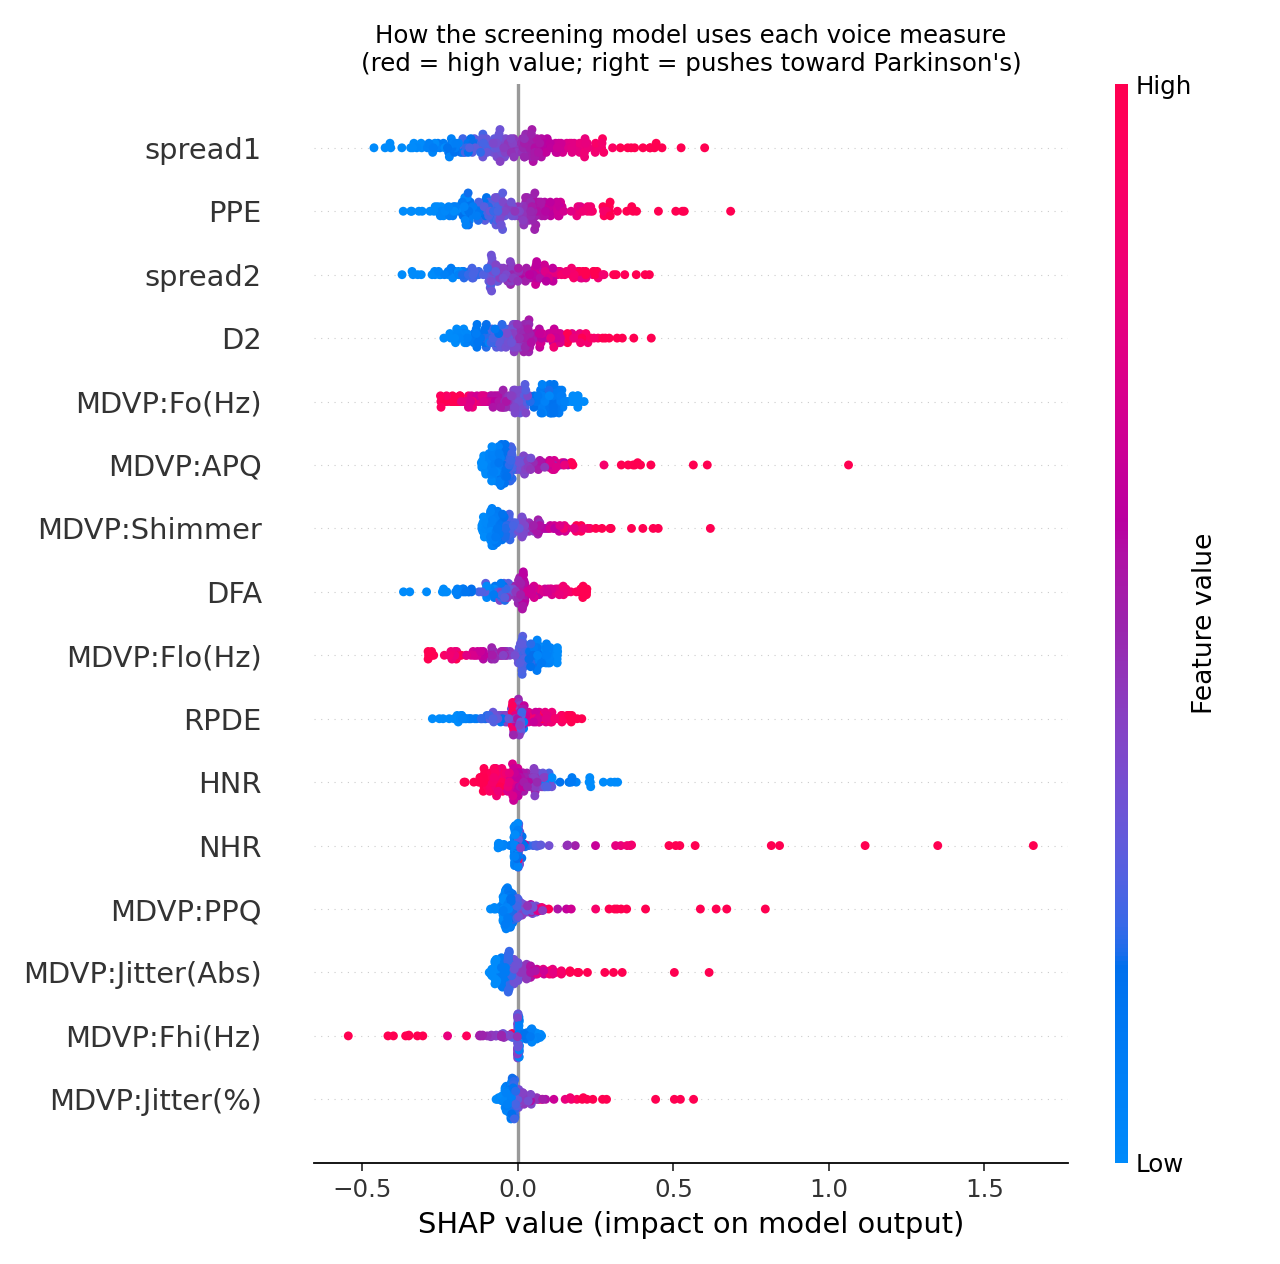

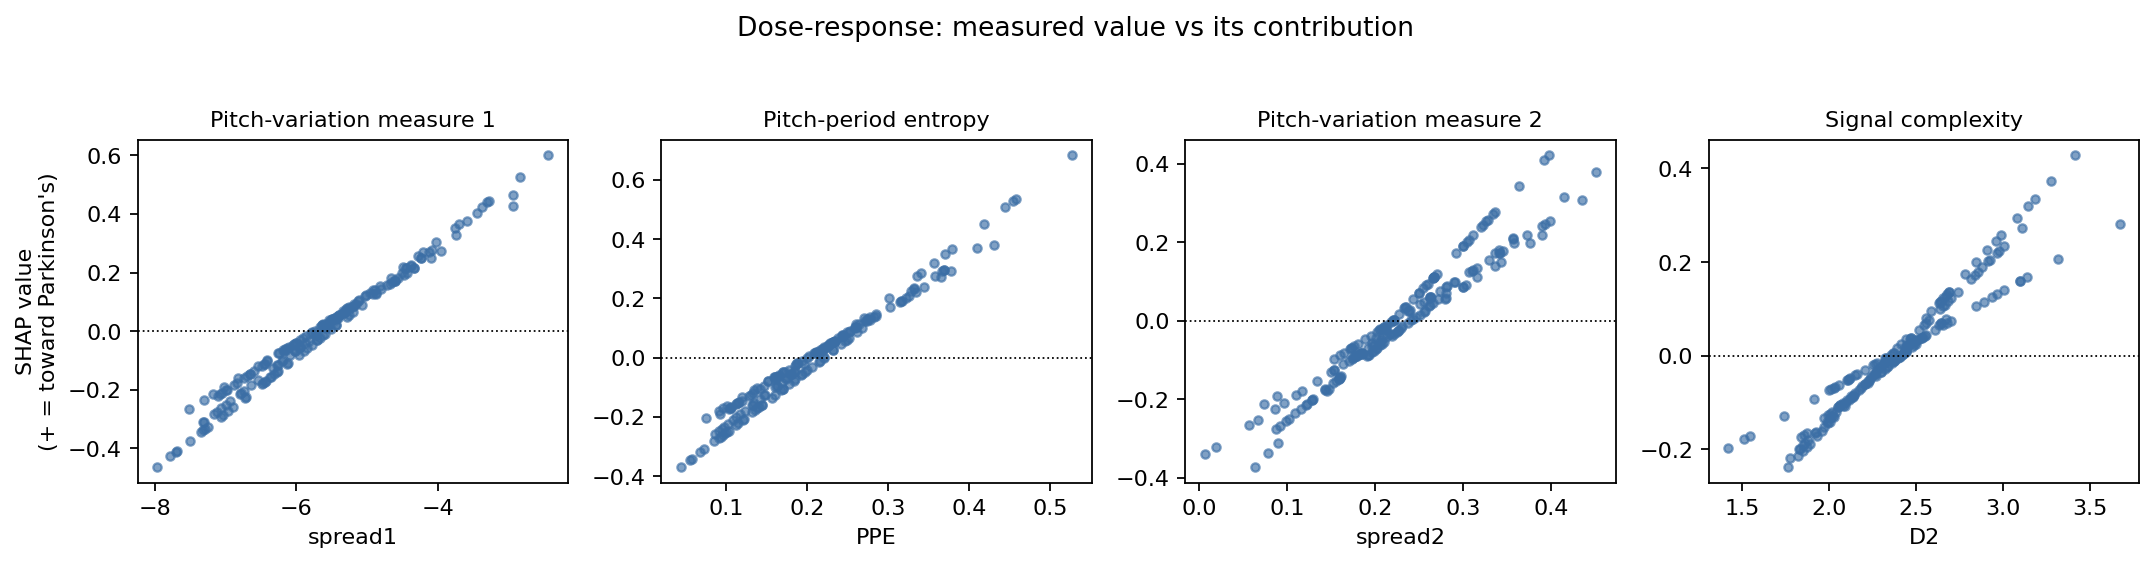

In [10]:
display(Image(filename=str(FIGURES_DIR / "biomarker_beeswarm.png")))
display(Image(filename=str(FIGURES_DIR / "biomarker_dependence.png")))

The model's own attributions agree with the univariate statistics of Section 2:
`spread1` and `PPE` dominate, both raising predicted risk when high. Average pitch
(`MDVP:Fo`) acts in the opposite direction — a higher, better-sustained pitch lowers
predicted risk.

### Per-speaker explanation cards

The deliverable of an explainable screening tool is not a global bar chart, it is a
per-patient answer to "why was I flagged?". Below: one true positive, one true
negative, one false positive and one false negative, all held out of training.

,y_true,y_prob,pred,outcome
subject,,,,
S01,1,0.859,1,true positive
S07,0,0.190,0,true negative
S13,0,0.531,1,false positive
S25,1,0.315,0,false negative


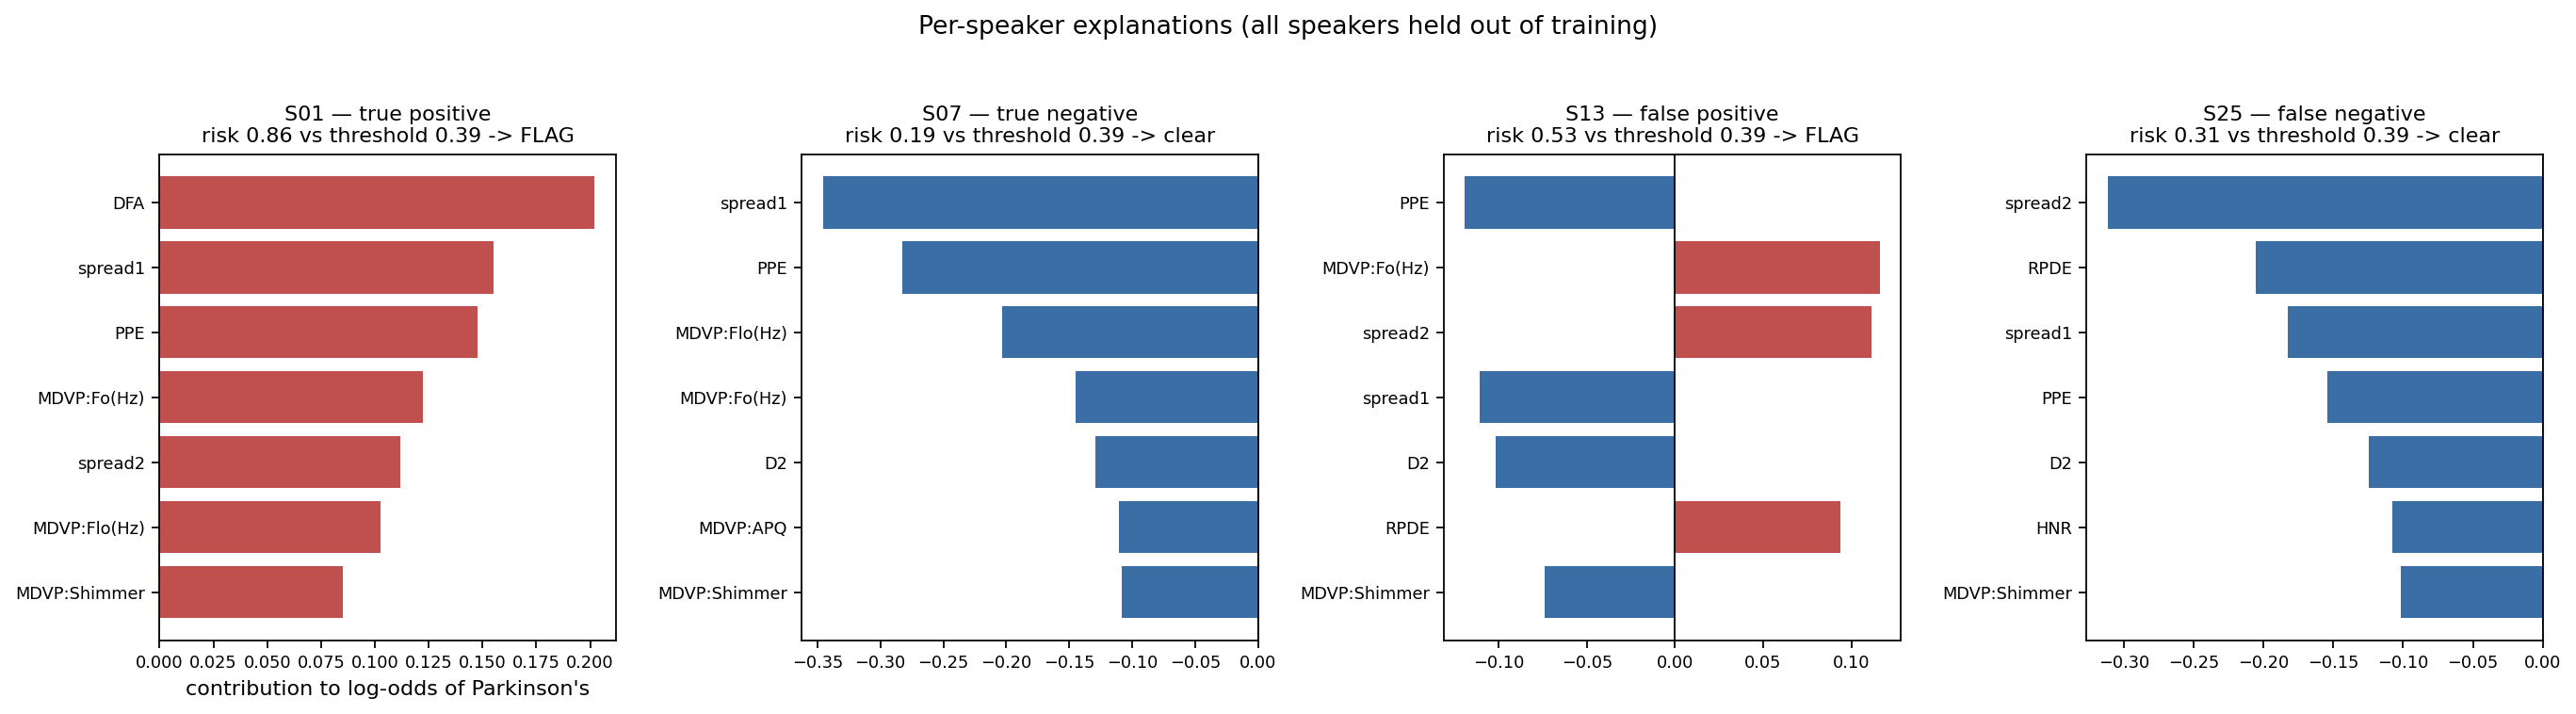

In [11]:
cards = pd.read_csv(TABLES_DIR / "patient_cards.csv", index_col=0)
display(cards[["y_true", "y_prob", "pred", "outcome"]].round(3))
display(Image(filename=str(FIGURES_DIR / "patient_cards.png")))

The false negative (S25) is the instructive one: this speaker has Parkinson's but
scores 0.32, below the flag threshold. Their pitch-variation measures sit in the
healthy range. A voice test cannot detect a patient whose voice is not yet affected,
and that is a limit of the modality rather than of the model.

## 6. Parsimony: one feature beats sixteen

If `spread1` carries most of the signal, what do the other fifteen features buy?
Each row below is a complete model, refit under the identical speaker-grouped
protocol with `C` tuned the same way.

In [12]:
sf = pd.read_csv(TABLES_DIR / "single_feature_cv.csv")
display(sf.round(3))
best1 = sf.iloc[0]; allf = sf[sf.model.str.startswith("ALL")].iloc[0]
print(f"\n{best1.model} alone : speaker-level AUC {best1.speaker_auc:.3f} "
      f"+/- {best1.speaker_sd:.3f}  (1 feature)")
print(f"All features       : speaker-level AUC {allf.speaker_auc:.3f} "
      f"+/- {allf.speaker_sd:.3f}  ({int(allf.n_features)} features)")
print(f"\nDifference: {best1.speaker_auc - allf.speaker_auc:+.3f} AUC in favour "
      f"of the single feature, with {allf.speaker_sd/best1.speaker_sd:.1f}x "
      f"less run-to-run variance.")

,model,n_features,recording_auc,recording_sd,speaker_auc,speaker_sd
0,spread1,1,0.892,0.005,0.924,0.005
1,PPE,1,0.892,0.006,0.920,0.006
2,spread2,1,0.800,0.008,0.847,0.012
3,MDVP:APQ,1,0.814,0.021,0.851,0.020
4,ALL 16 FEATURES,16,0.830,0.024,0.847,0.038



spread1 alone : speaker-level AUC 0.924 +/- 0.005  (1 feature)
All features       : speaker-level AUC 0.847 +/- 0.038  (16 features)

Difference: +0.077 AUC in favour of the single feature, with 8.0x less run-to-run variance.


**This is the most useful thing XAI produced here.** The explanation was not
decoration on top of a model — it identified that a one-variable model is both more
accurate and eight times more stable than the sixteen-variable one. At 32 speakers,
the additional features are fitting noise.

A deployable version of this work should be a two-feature model (`spread1`, `PPE`),
not an ensemble over 22 acoustic measures.

## 7. Validity: why the split is grouped by speaker

Every number above uses `StratifiedGroupKFold` on speaker ID. This section shows what
happens without it, because the alternative is what most published notebooks on this
dataset do.

Splitting 195 recordings at random puts five of a person's six recordings in training
and the sixth in test. The model can score well by recognising a voice it has already
heard. A 39-row random test set contains roughly **6 independent people**.

In [13]:
lk = pd.read_csv(TABLES_DIR / "leakage_optimism_roc_auc.csv")
display(lk[["model", "roc_auc_record", "roc_auc_subject", "optimism",
            "ci95_low", "ci95_high", "p_value"]].round(4))
print(f"Mean inflation: "
      f"{lk[lk.model!='Baseline (majority)'].optimism.mean():+.3f} AUC")
print(f"Models significantly inflated at p<0.001: "
      f"{int((lk.p_value<0.001).sum())} of {len(lk)-1}")

,model,roc_auc_record,roc_auc_subject,optimism,ci95_low,ci95_high,p_value
0,Gradient Boosting,0.9465,0.6791,0.2674,0.2106,0.3242,0.0000
1,XGBoost,0.9477,0.7173,0.2304,0.1875,0.2733,0.0000
2,k-NN,0.9700,0.7604,0.2096,0.1834,0.2358,0.0000
3,MLP,0.9654,0.7798,0.1857,0.1525,0.2188,0.0000
4,Random Forest,0.9546,0.7805,0.1742,0.1494,0.1989,0.0000
5,Extra Trees,0.9748,0.8158,0.1589,0.1424,0.1755,0.0000
6,LDA,0.8572,0.7051,0.1521,0.1317,0.1725,0.0000
7,SVM (RBF),0.9571,0.8131,0.1441,0.1196,0.1685,0.0000
8,SVM (linear),0.8789,0.7882,0.0906,0.0634,0.1179,0.0001
9,Gaussian NB,0.8638,0.7940,0.0698,0.0492,0.0904,0.0001


Mean inflation: +0.159 AUC
Models significantly inflated at p<0.001: 11 of 11


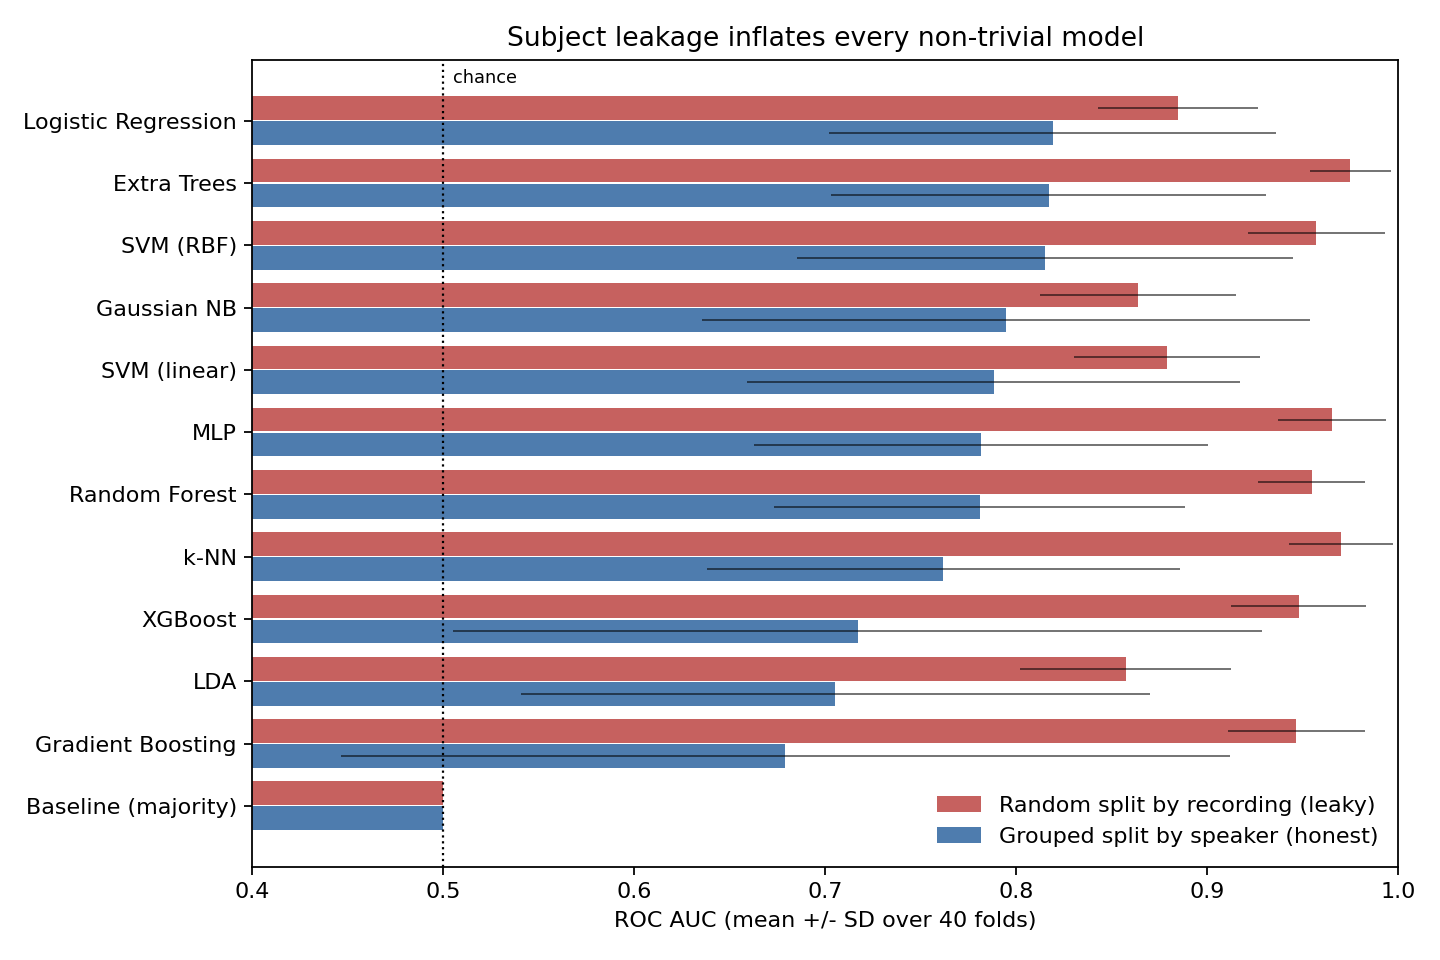

In [14]:
display(Image(filename=str(FIGURES_DIR / "protocol_gap_roc_auc.png")))

In [15]:
rep = json.loads((RESULTS_DIR / "analysis_report.json").read_text())
print(json.dumps(rep["ranking"], indent=2))

{
  "best_under_leaky_protocol": "Extra Trees",
  "best_under_honest_protocol": "Logistic Regression",
  "spearman_rank_correlation_between_protocols": 0.1909,
  "spearman_p": 0.5739
}


The inflation is large (+0.159 AUC on average), but the second consequence is worse:
the two protocols rank the models almost independently (Spearman 0.19, *p* = 0.57).
Extra Trees looks best under the leaky split and Logistic Regression is best under the
honest one. **A model chosen on a leaky benchmark is chosen at random.**

This also explains a familiar number. The commonly reported ~95% accuracy on this
dataset is a single draw from the red distribution below, not a generalisation
estimate.

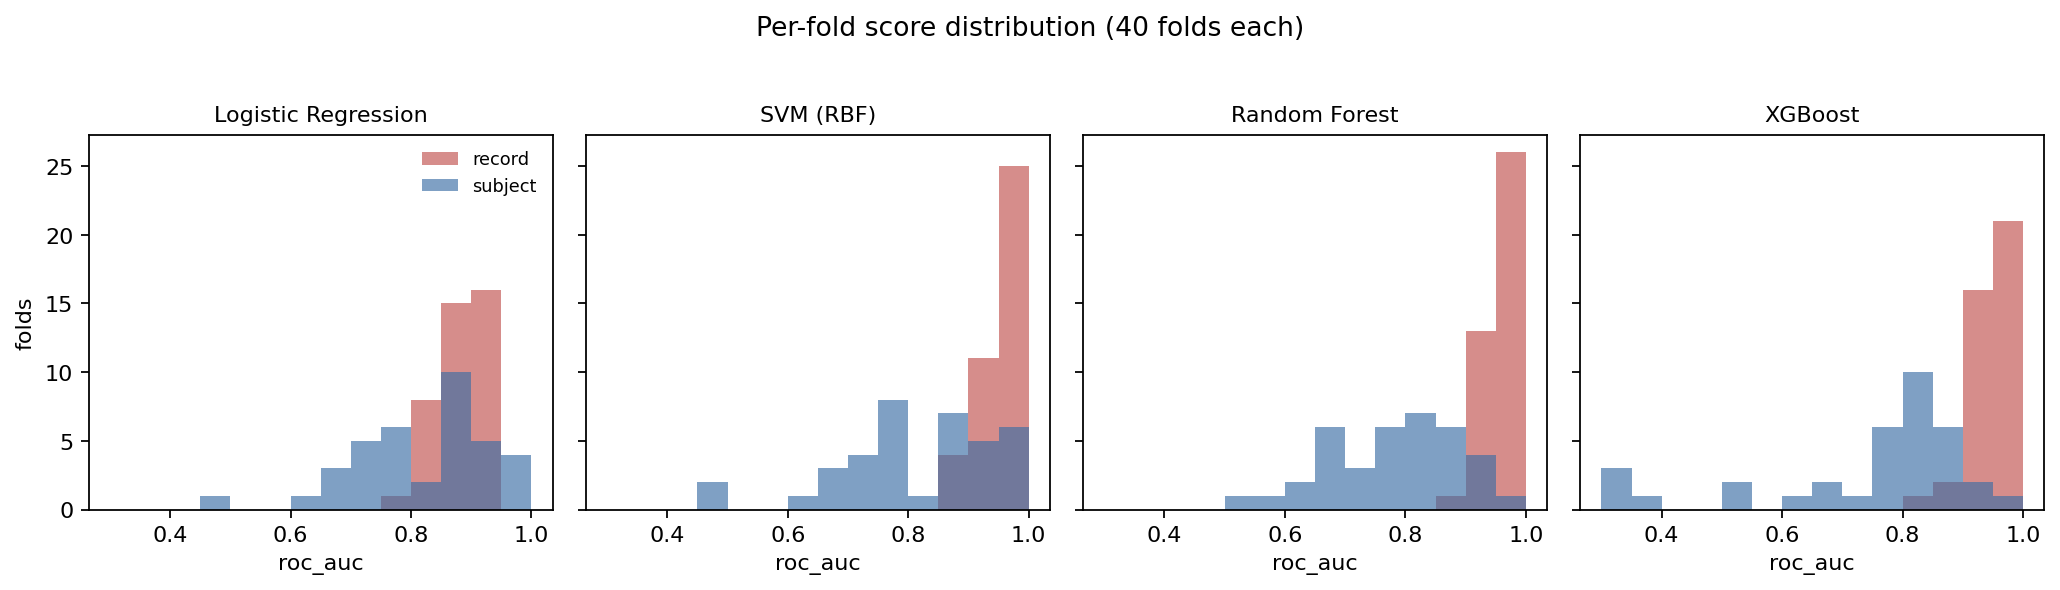

Random Forest          honest AUC across folds: 0.523 - 1.000
Logistic Regression    honest AUC across folds: 0.473 - 1.000


In [16]:
display(Image(filename=str(FIGURES_DIR / "fold_distributions.png")))
for m in ["Random Forest", "Logistic Regression"]:
    v = folds[(folds.model == m) & (folds.protocol == "subject")].roc_auc
    print(f"{m:22s} honest AUC across folds: {v.min():.3f} - {v.max():.3f}")

### Stability of the explanations

Explanations deserve the same scepticism as scores. Refitting and re-explaining
across 12 speaker-disjoint folds:

mean pairwise Spearman between fold rankings: 0.542
worst pair: -0.215


,mean_abs_shap,sd_across_folds,mean_rank,rank_sd
spread1,0.0847,0.0276,1.9167,1.3790
PPE,0.0701,0.0244,3.3333,2.0597
spread2,0.0535,0.0369,5.0833,3.6546
MDVP:APQ,0.0385,0.0158,5.3333,2.3094
MDVP:Fhi(Hz),0.0357,0.0183,6.5000,4.1010
MDVP:Shimmer,0.0313,0.0108,7.2500,2.1794
MDVP:Fo(Hz),0.0286,0.0115,7.3333,2.4618
NHR,0.0297,0.0194,7.6667,4.4789


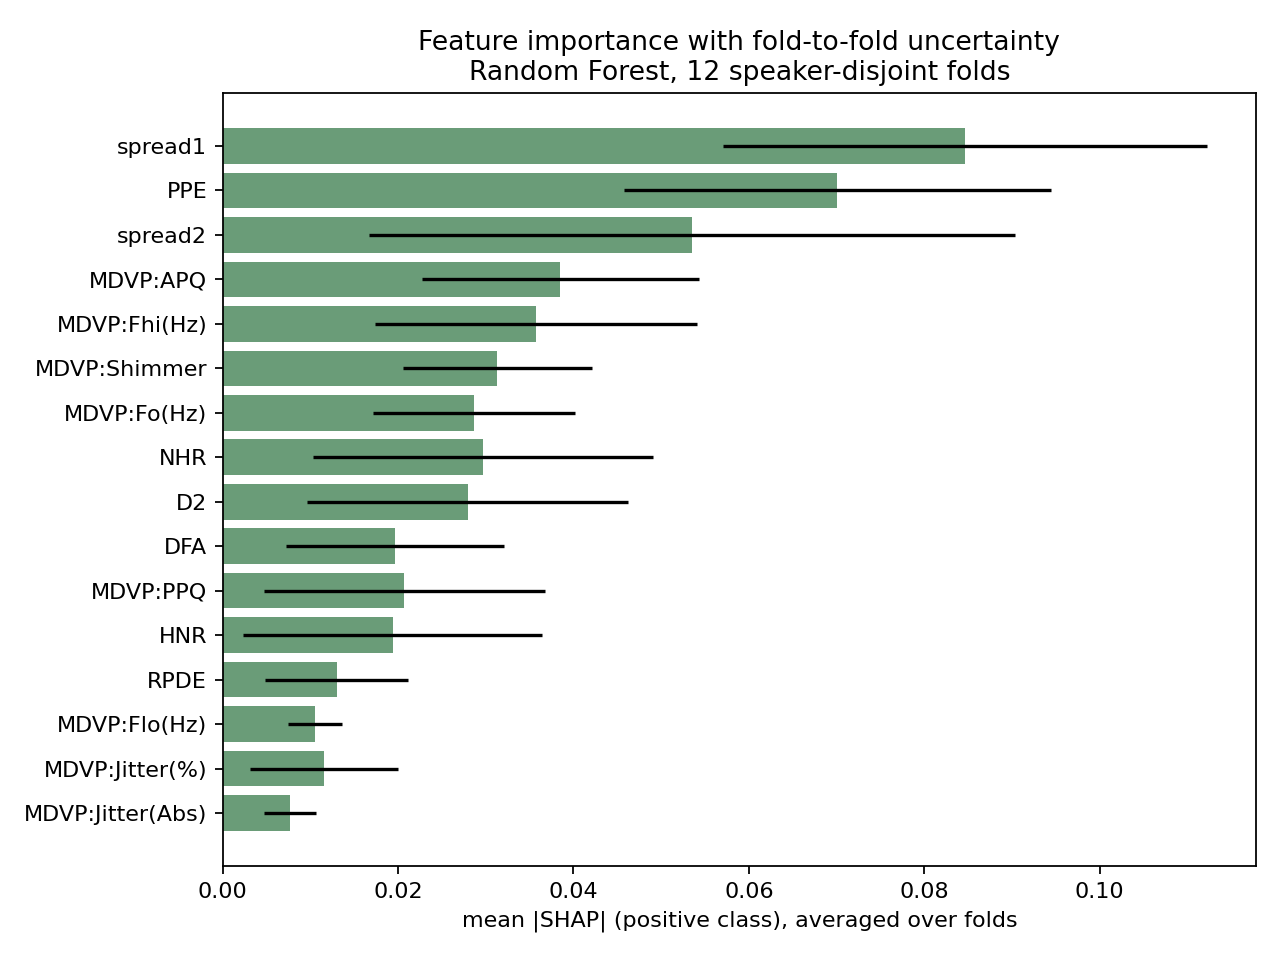

In [17]:
rep_s = json.loads((RESULTS_DIR / "shap_stability_report.json").read_text())
print("mean pairwise Spearman between fold rankings:",
      round(rep_s["mean_pairwise_spearman"], 3))
print("worst pair:", round(rep_s["min_pairwise_spearman"], 3))
display(pd.read_csv(TABLES_DIR / "shap_stability.csv", index_col=0).round(4).head(8))
display(Image(filename=str(FIGURES_DIR / "shap_stability.png")))

Only `spread1` and `PPE` rank consistently. Everything below them reorders from fold
to fold, which is why Section 6's conclusion is stated as a two-feature model rather
than a ranked list of ten biomarkers.

*Implementation note.* For binary classification `shap.TreeExplainer` returns an array
of shape `(n, features, 2)` whose class slices are symmetric, so averaging over the
class axis returns approximately zero. Measured on this data: **1.35e-17** for the
class-mean versus **3.16e-02** for the positive-class slice. Attribution plots built
on the class-mean show floating-point noise.

## 8. Conclusions

**On prediction.** Voice-based screening for Parkinson's is feasible but not
diagnostic. Held-out speaker-level ROC-AUC is **0.852**; at a 90%-sensitivity
operating point the test catches 92% of cases at **48.8% specificity**. It is a
triage instrument, not a diagnosis.

**On explainability.** The dominant signal is impaired control of pitch — `spread1`
and `PPE`, both raised in Parkinson's with *d* > 1.9. Classical jitter and shimmer
measures matter less than the nonlinear descriptors. Per-speaker SHAP cards make each
flag auditable, including the failures.

**On modelling.** A one-feature logistic regression (**0.924 AUC**) outperforms the
full 16-feature model (**0.847**) with far lower variance. Complexity is not rewarded
at this sample size.

**On methodology.** Speaker-grouped validation is not optional on this dataset.
Ignoring it inflates ROC-AUC by +0.159 on average and makes model selection
meaningless.

## Limitations

* **32 speakers, 8 of them healthy.** Every specificity estimate rests on 8 people.
  Confidence intervals are wide; treat all figures as approximate.
* **Single session, single site.** One cohort, one recording setup (Little et al.,
  2007). Nothing here establishes generalisation across microphones, languages,
  recording conditions, or disease stage.
* **No external validation set.** All figures are cross-validation estimates. At this
  sample size a held-out set would be too small to be informative.
* **Cross-sectional, not diagnostic.** Speakers already carry a diagnosis; this does
  not demonstrate early detection, and no severity or medication state is modelled.
* **Not a medical device.** This is a methodology and explainability study on a public
  benchmark.

## Data citation

Little, M., McSharry, P., Roberts, S., Costello, D., & Moroz, I. (2007).
*Exploiting nonlinear recurrence and fractal scaling properties for voice disorder
detection.* BioMedical Engineering OnLine, 6:23.
Dataset: UCI Machine Learning Repository, "Parkinsons" (ID 174), CC BY 4.0.